In [6]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.datasets import load_iris
from model.kmeans import KMeans

bài 2: phân cụm iris bằng kmeans from scratch
(model xây dựng trong /model/kmeans.py)

In [ ]:
data = load_iris(as_frame=True)
data = data.frame

data.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [ ]:
# plot the data to the from scratch algoritm
X = data[data.columns[:2]].to_numpy()
y = data["target"].to_numpy()

model = KMeans()
res_center, label, it = model.fit(X, 3, 100)
print(res_center, label, it)

[[5.77358491 2.69245283]
 [6.81276596 3.07446809]
 [5.006      3.428     ]] [2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 1 1 1 0 1 0 1 0 1 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0
 1 1 1 1 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 1 1 1 1 0 1 1 1 1
 1 1 0 0 1 1 1 1 0 1 0 1 0 1 1 0 0 1 1 1 1 1 0 0 1 1 1 0 1 1 1 0 1 1 1 0 1
 1 0] 12


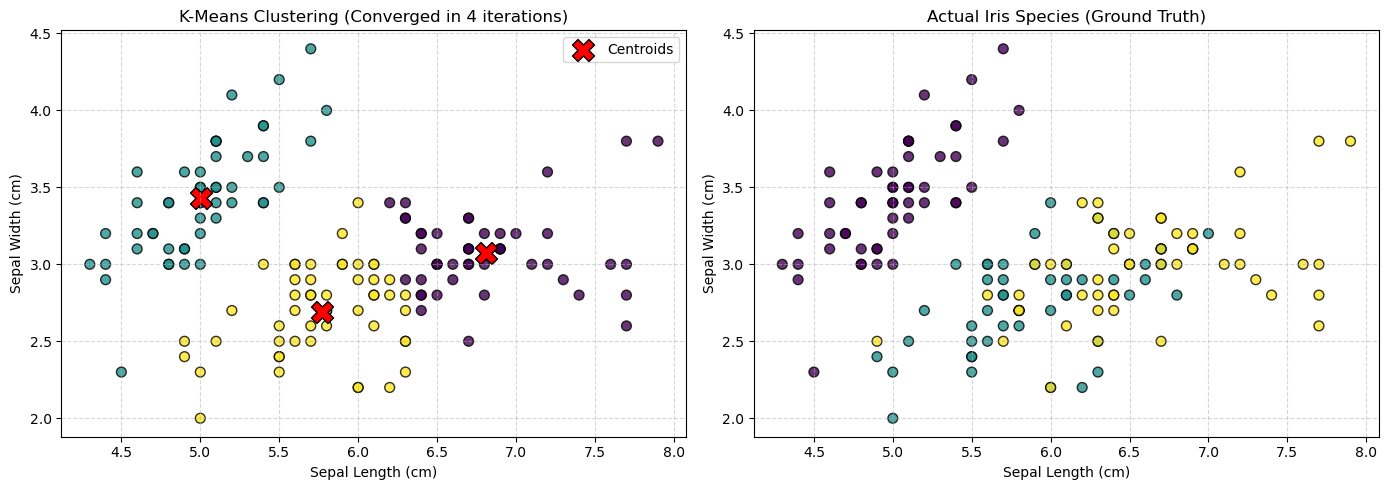

In [ ]:
# visualization
X_np = np.asarray(X)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: K-Means Predicted Clusters & Centroids
scatter1 = axes[0].scatter(
    X_np[:, 0], X_np[:, 1], 
    c=label, cmap='viridis', s=50, alpha=0.8, edgecolors='k'
)
axes[0].scatter(
    res_center[:, 0], res_center[:, 1], 
    c='red', marker='X', s=250, edgecolors='black', label='Centroids'
)
axes[0].set_title(f'K-Means Clustering (Converged in {it} iterations)')
axes[0].set_xlabel('Sepal Length (cm)')
axes[0].set_ylabel('Sepal Width (cm)')
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.5)

# Plot 2: Actual Ground Truth Labels
scatter2 = axes[1].scatter(
    X_np[:, 0], X_np[:, 1], 
    c=y, cmap='viridis', s=50, alpha=0.8, edgecolors='k'
)
axes[1].set_title('Ground Truth')
axes[1].set_xlabel('Sepal Length (cm)')
axes[1].set_ylabel('Sepal Width (cm)')
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

bài 3: Xác định k bằng elbow method

c:\Users\Admin\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
c:\Users\Admin\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
c:\Users\Admin\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
c:\Users\Admin\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Window

1 30210.765042399427
2 14726.117037953445
3 3648.763582876105
4 3027.754035966964
5 923.9931490057969
6 843.7677420832543
7 769.5451688467292
8 714.6573133215312
9 673.0203258974311
10 640.3899290761109


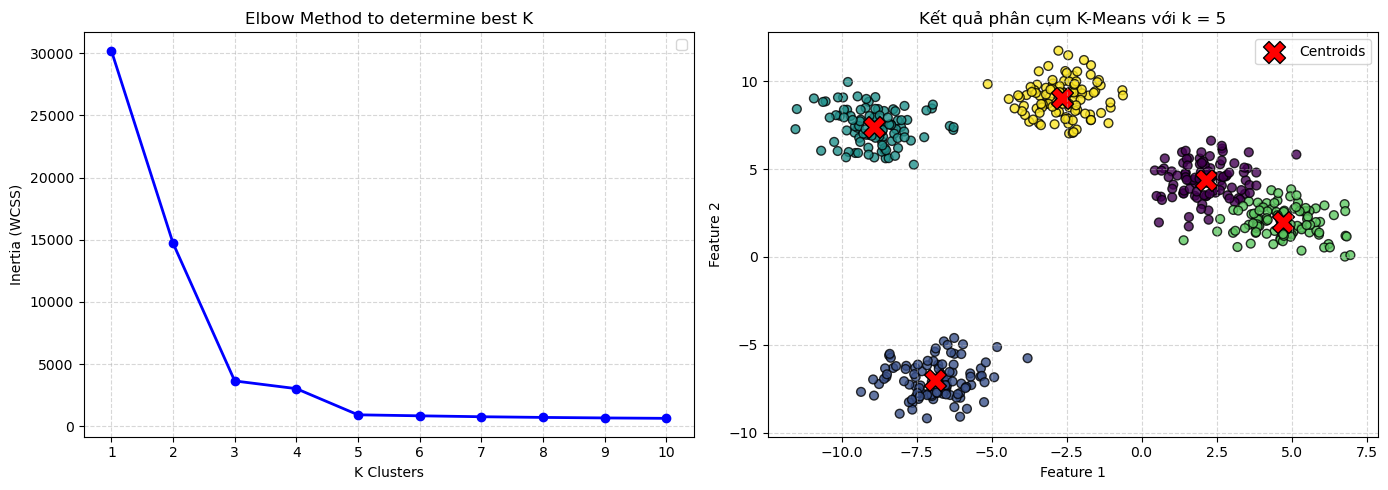

In [ ]:
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs

X, y_true = make_blobs(
    n_samples= 500,
    n_features= 2, # for visualization
    centers= 5,
    random_state= 42
)

inertias = []
for i in range(1, 11):
    model = KMeans(n_clusters= i, max_iter=100, random_state= 0, n_init="auto").fit(X)
    inertias.append(model.inertia_)
    print(i, model.inertia_)

# visualize the inertia changes to observe the elbow
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
k_values = range(1, 11)
axes[0].plot(k_values, inertias, marker='o', linestyle='-', color='b', linewidth=2)
axes[0].set_title('Elbow Method to determine best K')
axes[0].set_xlabel('K Clusters')
axes[0].set_ylabel('Inertia (WCSS)')
axes[0].set_xticks(k_values)
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.5)

# ta có thể thấy trong biểu đồ, giá trị k=5 là số cụm tối ưu (inertia change from k=5 -> k=6 rất nhỏ)
# visualize dữ liệu với k=5
best_model = KMeans(n_clusters=5, max_iter=100, random_state=0, n_init="auto").fit(X)
axes[1].scatter(X[:, 0], X[:, 1], c=best_model.labels_, cmap='viridis', s=40, alpha=0.8, edgecolors='k')
axes[1].scatter(
    best_model.cluster_centers_[:, 0], best_model.cluster_centers_[:, 1], 
    c='red', marker='X', s=250, edgecolors='black', label='Centroids'
)
axes[1].set_title('Kết quả phân cụm K-Means với k = 5')
axes[1].set_xlabel('Feature 1')
axes[1].set_ylabel('Feature 2')
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()